# Modeling & evaluation — booking cancellation

Notebook này tạo baseline, tuning 4 thuật toán bằng Optuna với temporal CV, đánh giá trên cùng validation cohort, chọn threshold theo năng lực xử lý cảnh báo và xuất prediction/report khi chạy. Phạm vi model chính là population `individual`, theo thiết kế dự án; `group_block` cần quy tắc vận hành riêng.

**Notebook chưa được chạy.** Chạy tuần tự từ trên xuống sau khi cài dependencies. Kết quả và file output chỉ được sinh khi người dùng chạy notebook.

## Giới hạn dữ liệu và cách chia thời gian
- Target: `is_canceled`. Chia theo `arrival_date`: train đến 2016-06-30; validation 2016-07-01–2016-12-31; test từ 2017-01-01. Test chỉ được mở sau khi hoàn tất chọn model và threshold.
- Validation và cohort 2017 đã được xem trong notebook 03 EDA (xem `docs/F1_validation_design.md`); vì vậy đây là holdout theo workflow notebook này, **không phải untouched trong lịch sử dự án**. Kết quả 2017 cũng đã được xem trước đó.
- Dữ liệu nguồn là near-arrival snapshot. Một số trường, đặc biệt `lead_time` và các biến suy ra từ ngày đến/lead time, có thể khác giá trị thực sự biết tại thời điểm booking. Label maturity được xấp xỉ bằng `arrival_date` vì modeling dataset không có ngày label được xác nhận; đây là quy ước bảo thủ, không phải timestamp thực tế. Kết quả là retrospective prototype, không phải bằng chứng về hiệu năng production. Kiểm tra `docs/feature_availability.csv` và xác minh feature as-of trước triển khai.
- PR-AUC được tính bằng average precision (AP); event-rate baseline được báo cáo cạnh PR-AUC. Threshold được chọn riêng cho từng model trên validation với giới hạn cảnh báo tối đa 20%, rồi threshold của model cuối được đóng băng trước test.


**Thay đổi v2 so với bản trước** (đã xoá toàn bộ output cũ; chạy lại tuần tự từ trên xuống):
1. Temporal CV: 4 fold × 2 tháng thay vì 3 fold × 1 quý; `N_TRIALS` 15 → 40.
2. Bỏ `class_weight='balanced'` (đặt `CLASS_WEIGHT`), thêm hiệu chỉnh xác suất (`CALIBRATION`) fit trên OOF temporal; ngưỡng chọn lại trên xác suất đã calibrate.
3. Model cuối vẫn refit trên train + validation (đã có từ bản gốc) và calibrator fit lại trên OOF của cohort này; lưu thêm `final_model_bundle.joblib`.
4. Mục 7: lift@k, block-bootstrap CI, so sánh ghép cặp với 2 rule đơn giản, cumulative gain.
Test chưa được mở trong quá trình chỉnh sửa này.

In [1]:
# Nếu thiếu package, bỏ comment và chạy riêng dòng sau; notebook không cài package tự động.
# %pip install -r requirements.txt
from pathlib import Path
import json

from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
try:
    import optuna
except ImportError as exc:
    raise ImportError('Cài dependencies bằng %pip install -r requirements.txt để dùng Optuna.') from exc
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError('Cài dependencies bằng %pip install -r requirements.txt để dùng XGBoost.') from exc

SEED = 42
N_TRIALS = 40  # v2: tăng từ 15; 4 models x 40 trials x 4 folds (tune lâu hơn ~3.5 lần)
CLASS_WEIGHT = None      # v2: bỏ 'balanced' (làm xác suất bị lệch); đặt lại 'balanced' để so sánh
CALIBRATION = 'sigmoid'  # v2: 'sigmoid' (Platt) | 'isotonic' | None; fit trên OOF temporal, không phải trên validation
TOPK_SHARES = [0.05, 0.10, 0.20]  # v2: các mức hàng đợi cảnh báo để báo cáo lift@k
N_BOOT = 500             # v2: số lần block-bootstrap (theo tuần đến)
MAX_ALERT_SHARE = 0.20
MIN_SUBGROUP_SIZE = 100
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'processed' / 'modeling_dataset.csv').exists():
    candidates = [p for p in Path.cwd().parents if (p / 'data' / 'processed' / 'modeling_dataset.csv').exists()]
    if not candidates:
        raise FileNotFoundError('Không tìm thấy data/processed/modeling_dataset.csv; mở notebook từ thư mục gốc repo.')
    PROJECT_ROOT = candidates[0]
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'modeling_dataset.csv'
OUTPUT_DIR = PROJECT_ROOT / 'artifacts' / 'modeling'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)
print('Output folder:', OUTPUT_DIR)


Project root: c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2
Output folder: c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2\artifacts\modeling


## 1. Nạp dữ liệu, chọn feature và chia cohort

Feature lấy từ `config/column_groups.json` → `individual_model`, không tự suy diễn thêm cột. Loại các biến định danh/target/metadata, pre-arrival-only và ADR snapshot khỏi predictor. `market_segment` và `lead_time` được giữ theo cấu hình chính, nhưng lead-time band chỉ là diagnostic nếu chưa chứng minh được giá trị tồn tại tại score time.


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['arrival_date', 'booking_date'])
if 'is_canceled' not in df or 'arrival_date' not in df or 'split' not in df:
    raise ValueError('Dataset cần có is_canceled, arrival_date và split.')

column_config = json.loads((PROJECT_ROOT / 'config' / 'column_groups.json').read_text(encoding='utf-8'))
individual_config = column_config['individual_model']
pre_arrival_only = set(individual_config['pre_arrival_extra'])
snapshot_monetary = {'adr_clean', 'adr_vs_ref', 'adr_per_guest'}
numeric_candidates = [c for c in individual_config['numeric']
                      if c not in pre_arrival_only and c not in snapshot_monetary]
categorical_candidates = [c for c in individual_config['categorical'] if c not in pre_arrival_only]
numeric_features = [c for c in numeric_candidates if c in df.columns]
categorical_features = [c for c in categorical_candidates if c in df.columns]
not_found_features = [c for c in numeric_candidates + categorical_candidates if c not in df.columns]
feature_cols = numeric_features + categorical_features
if not feature_cols:
    raise ValueError('Không tìm thấy feature hợp lệ trong modeling_dataset.csv.')
print(f'{len(numeric_features)} numeric, {len(categorical_features)} categorical features')
print('Excluded from config: pre-arrival-only and monetary snapshot features; unavailable configured columns:', not_found_features)
print('Excluded identifiers/metadata/target: booking_id, population, split, dates, is_duplicate')

if 'population' not in df:
    raise ValueError('Dataset cần cột population để áp dụng scope individual đã thống nhất trong dự án.')
arrival = df['arrival_date']
individual = df['population'].eq('individual')
train_mask = individual & df['split'].eq('train') & arrival.le(pd.Timestamp('2016-06-30'))
validation_mask = individual & df['split'].eq('train') & arrival.between('2016-07-01', '2016-12-31')
test_mask = individual & df['split'].eq('test') & arrival.ge(pd.Timestamp('2017-01-01'))
train = df.loc[train_mask].copy()
validation = df.loc[validation_mask].copy()
test = df.loc[test_mask].copy()
if min(len(train), len(validation), len(test)) == 0:
    raise ValueError('Một cohort rỗng; kiểm tra lại split/date trong modeling_dataset.csv.')
assert train['arrival_date'].max() < validation['arrival_date'].min()
assert validation['arrival_date'].max() < test['arrival_date'].min()
assert set(train.index).isdisjoint(validation.index) and set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)

for name, part in [('train', train), ('validation', validation)]:
    if part['is_canceled'].isna().any() or not set(part['is_canceled'].unique()).issubset({0, 1}):
        raise ValueError(f'{name} cần nhãn is_canceled nhị phân 0/1, không null.')
cohort_summary = pd.DataFrame([
    {'cohort': name, 'rows': len(part), 'start': part['arrival_date'].min().date(),
     'end': part['arrival_date'].max().date(), 'event_rate': part['is_canceled'].mean()}
    for name, part in [('train', train), ('validation', validation)]
] + [{'cohort': 'test (locked until final evaluation)', 'rows': len(test),
      'start': test['arrival_date'].min().date(), 'end': test['arrival_date'].max().date(),
      'event_rate': 'not read until final evaluation'}])
display(cohort_summary)
print('Population scope: individual only; group_block is outside this classifier and needs its own operational policy.')
print('Historical status: validation/test labels were previously inspected in notebook 03 EDA; not historically untouched.')

X_train, y_train = train[feature_cols], train['is_canceled'].astype(int)
X_val, y_val = validation[feature_cols], validation['is_canceled'].astype(int)
train_event_rate = float(y_train.mean())
print(f'Train event-rate baseline (constant prediction): {train_event_rate:.4f}')


33 numeric, 7 categorical features
Excluded from config: pre-arrival-only and monetary snapshot features; unavailable configured columns: []
Excluded identifiers/metadata/target: booking_id, population, split, dates, is_duplicate


,cohort,rows,start,end,event_rate
0,train,17440,2015-07-01,2016-06-30,0.251089
1,validation,14837,2016-07-01,2016-12-31,0.314821
2,test (locked until final evaluation),20399,2017-01-01,2017-08-31,not read until final evaluation


Population scope: individual only; group_block is outside this classifier and needs its own operational policy.
Historical status: validation/test labels were previously inspected in notebook 03 EDA; not historically untouched.
Train event-rate baseline (constant prediction): 0.2511


## 2. Temporal CV và Optuna tuning

Bốn expanding-origin folds (mỗi fold validate 2 tháng) chỉ dùng train cohort. Imputer, scaler, encoder và model đều được fit lại bên trong từng fold. Validation/test không tham gia Optuna. Dense one-hot encoding được dùng để tương thích với HistGradientBoosting; nếu feature cardinality tăng đáng kể, cần xem lại memory footprint.


In [3]:
# v2: 4 fold, mỗi fold validate 2 tháng -> điểm CV là trung bình của nhiều cửa sổ hơn, ít phụ thuộc 1 quý bất thường
FOLD_WINDOWS = [
    ('fold_1', '2015-10-31', '2015-11-01', '2015-12-31'),
    ('fold_2', '2015-12-31', '2016-01-01', '2016-02-29'),
    ('fold_3', '2016-02-29', '2016-03-01', '2016-04-30'),
    ('fold_4', '2016-04-30', '2016-05-01', '2016-06-30'),
]
folds = []
for fold_name, fit_end, valid_start, valid_end in FOLD_WINDOWS:
    fit_mask = train['arrival_date'].le(pd.Timestamp(fit_end))
    fold_valid_mask = train['arrival_date'].between(valid_start, valid_end)
    fit_idx, valid_idx = train.index[fit_mask], train.index[fold_valid_mask]
    if len(fit_idx) == 0 or len(valid_idx) == 0:
        raise ValueError(f'{fold_name} rỗng; kiểm tra time range.')
    if y_train.loc[valid_idx].nunique() != 2 or y_train.loc[fit_idx].nunique() != 2:
        raise ValueError(f'{fold_name} cần đủ hai lớp ở fit và validation.')
    assert train.loc[fit_idx, 'arrival_date'].max() < train.loc[valid_idx, 'arrival_date'].min()
    folds.append((fold_name, fit_idx, valid_idx))
display(pd.DataFrame([{'fold': n, 'fit_rows': len(i), 'fit_through': train.loc[i, 'arrival_date'].max().date(),
                       'valid_rows': len(j), 'valid_from': train.loc[j, 'arrival_date'].min().date(),
                       'valid_to': train.loc[j, 'arrival_date'].max().date()} for n, i, j in folds]))

baseline_features = [c for c in ['lead_time', 'market_segment'] if c in feature_cols]
baseline_numeric = [c for c in baseline_features if c in numeric_features]
baseline_categorical = [c for c in baseline_features if c in categorical_features]
if not baseline_features:
    raise ValueError('Baseline LR richiede lead_time o market_segment.')

def make_pipeline(model_name, params=None):
    params = dict(params or {})
    scale_numeric = model_name in {'logistic_regression', 'baseline_logistic'}
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    transformers = [('num', Pipeline(numeric_steps), numeric_features)]
    if categorical_features:
        cat_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])
        transformers.append(('cat', cat_pipe, categorical_features))
    prep = ColumnTransformer(transformers, remainder='drop', sparse_threshold=0.0)
    if model_name in {'logistic_regression', 'baseline_logistic'}:
        estimator = LogisticRegression(class_weight=CLASS_WEIGHT, max_iter=2000, random_state=SEED, **params)
    elif model_name == 'random_forest':
        estimator = RandomForestClassifier(class_weight=CLASS_WEIGHT, n_jobs=-1,
                                           random_state=SEED, **params)
    elif model_name == 'xgboost':
        estimator = XGBClassifier(objective='binary:logistic', eval_metric='logloss', n_jobs=-1,
                                  tree_method='hist', random_state=SEED, **params)
    elif model_name == 'hist_gradient_boosting':
        estimator = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params)
    else:
        raise ValueError(f'Unknown model: {model_name}')
    return Pipeline([('preprocess', prep), ('model', estimator)])

def make_baseline_pipeline():
    transformers = []
    if baseline_numeric:
        transformers.append(('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                                ('scale', StandardScaler())]), baseline_numeric))
    if baseline_categorical:
        transformers.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                                ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
                             baseline_categorical))
    prep = ColumnTransformer(transformers, remainder='drop', sparse_threshold=0.0)
    model = LogisticRegression(class_weight=CLASS_WEIGHT, max_iter=2000, random_state=SEED)
    return Pipeline([('preprocess', prep), ('model', model)])

def suggest_params(trial, model_name):
    if model_name == 'logistic_regression':
        return {'C': trial.suggest_float('C', 1e-3, 100, log=True),
                'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear'])}
    if model_name == 'random_forest':
        return {'n_estimators': trial.suggest_int('n_estimators', 200, 600, step=100),
                'max_depth': trial.suggest_int('max_depth', 4, 24),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
                'max_features': trial.suggest_categorical('max_features', ['sqrt', 0.5, 0.8])}
    if model_name == 'xgboost':
        return {'n_estimators': trial.suggest_int('n_estimators', 200, 700, step=100),
                'max_depth': trial.suggest_int('max_depth', 2, 8),
                'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
                'subsample': trial.suggest_float('subsample', 0.7, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
                'min_child_weight': trial.suggest_float('min_child_weight', 1, 12),
                'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 20, log=True)}
    return {'max_iter': trial.suggest_int('max_iter', 100, 400, step=50),
            'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
            'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 15, 63),
            'l2_regularization': trial.suggest_float('l2_regularization', 1e-4, 10, log=True),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 10, 60)}

MODEL_NAMES = ['logistic_regression', 'random_forest', 'xgboost', 'hist_gradient_boosting']
best_params, cv_summary, studies = {}, [], {}
for model_name in MODEL_NAMES:
    def objective(trial, model_name=model_name):
        params = suggest_params(trial, model_name)
        fold_scores = []
        for fold_name, fit_idx, valid_idx in folds:
            estimator = make_pipeline(model_name, params)
            estimator.fit(train.loc[fit_idx, feature_cols], y_train.loc[fit_idx])
            probability = estimator.predict_proba(train.loc[valid_idx, feature_cols])[:, 1]
            fold_scores.append(average_precision_score(y_train.loc[valid_idx], probability))
        trial.set_user_attr('fold_scores', fold_scores)
        return float(np.mean(fold_scores))
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    studies[model_name] = study
    best_params[model_name] = study.best_params
    scores = np.asarray(study.best_trial.user_attrs['fold_scores'], dtype=float)
    cv_summary.append({'model': model_name, 'cv_pr_auc_mean': scores.mean(),
                       'cv_pr_auc_std': scores.std(ddof=1), 'cv_pr_auc_min': scores.min(),
                       'cv_pr_auc_max': scores.max(), 'best_params': json.dumps(study.best_params),
                       **{f'{folds[i][0]}_pr_auc': score for i, score in enumerate(scores)}})
baseline_fold_scores = []
for fold_name, fit_idx, valid_idx in folds:
    baseline_fold = make_baseline_pipeline()
    baseline_fold.fit(train.loc[fit_idx, baseline_features], y_train.loc[fit_idx])
    baseline_probability = baseline_fold.predict_proba(train.loc[valid_idx, baseline_features])[:, 1]
    baseline_fold_scores.append(average_precision_score(y_train.loc[valid_idx], baseline_probability))
baseline_scores = np.asarray(baseline_fold_scores, dtype=float)
cv_summary.append({'model': 'baseline_logistic', 'cv_pr_auc_mean': baseline_scores.mean(),
                   'cv_pr_auc_std': baseline_scores.std(ddof=1), 'cv_pr_auc_min': baseline_scores.min(),
                   'cv_pr_auc_max': baseline_scores.max(), 'best_params': '{}',
                   **{f'{folds[i][0]}_pr_auc': score for i, score in enumerate(baseline_scores)}})
cv_results = pd.DataFrame(cv_summary).set_index('model')
display(cv_results)
print('Temporal CV score = mean AP across the expanding-origin folds; std is a stability diagnostic.')


,fold,fit_rows,fit_through,valid_rows,valid_from,valid_to
0,fold_1,3877,2015-10-31,1722,2015-11-01,2015-12-31
1,fold_2,5599,2015-12-31,2665,2016-01-01,2016-02-29
2,fold_3,8264,2016-02-29,4804,2016-03-01,2016-04-30
3,fold_4,13068,2016-04-30,4372,2016-05-01,2016-06-30


  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

c:\Users\Admin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Admin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Admin\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Admin\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Admin\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_min,cv_pr_auc_max,best_params,fold_1_pr_auc,fold_2_pr_auc,fold_3_pr_auc,fold_4_pr_auc
model,,,,,,,,,
logistic_regression,0.528067,0.193100,0.383503,0.812842,"{""C"": 86.78162918126168, ""solver"": ""liblinear""}",0.812842,0.383503,0.453639,0.462285
random_forest,0.546899,0.181649,0.422675,0.813593,"{""n_estimators"": 600, ""max_depth"": 17, ""min_sa...",0.813593,0.441880,0.509447,0.422675
xgboost,0.544121,0.163338,0.437986,0.785346,"{""n_estimators"": 300, ""max_depth"": 8, ""learnin...",0.785346,0.437986,0.503594,0.449560
hist_gradient_boosting,0.542088,0.183334,0.414772,0.811873,"{""max_iter"": 300, ""learning_rate"": 0.025869008...",0.811873,0.414772,0.499942,0.441766
baseline_logistic,0.345203,0.012624,0.328066,0.357676,{},0.357676,0.350534,0.344534,0.328066


Temporal CV score = mean AP across the expanding-origin folds; std is a stability diagnostic.


### Hiệu chỉnh xác suất (v2)

Calibrator được fit trên **out-of-fold predictions của temporal CV** (không dùng validation/test để fit), rồi áp lên xác suất validation. Platt (sigmoid) là biến đổi đơn điệu nên không đổi PR-AUC/ROC-AUC; chỉ đổi thang xác suất (Brier, calibration curve, ngưỡng). Với model cuối, calibrator được fit lại trên OOF của train + validation. Nếu event rate đổi theo thời gian (drift), calibration vẫn lệch một phần: đó là hạn chế thật, không phải lỗi code.

In [4]:
from sklearn.isotonic import IsotonicRegression

FINAL_CAL_WINDOWS = FOLD_WINDOWS + [
    ('fold_5', '2016-06-30', '2016-07-01', '2016-09-30'),
    ('fold_6', '2016-09-30', '2016-10-01', '2016-12-31'),
]

def build_estimator(name, params=None):
    return make_baseline_pipeline() if name == 'baseline_logistic' else make_pipeline(name, params)

def oof_probabilities(name, params, frame, feats, fold_defs):
    # Out-of-fold probabilities: mỗi cửa sổ được dự báo bởi model chỉ fit trên dữ liệu đến trước cửa sổ đó.
    ps, ys = [], []
    for _, fit_end, valid_start, valid_end in fold_defs:
        fit_part = frame[frame['arrival_date'].le(pd.Timestamp(fit_end))]
        valid_part = frame[frame['arrival_date'].between(valid_start, valid_end)]
        est = build_estimator(name, params)
        est.fit(fit_part[feats], fit_part['is_canceled'].astype(int))
        ps.append(est.predict_proba(valid_part[feats])[:, 1])
        ys.append(valid_part['is_canceled'].astype(int).to_numpy())
    return np.concatenate(ps), np.concatenate(ys)

def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def fit_calibrator(p, y, method='sigmoid'):
    if method == 'isotonic':
        return IsotonicRegression(out_of_bounds='clip').fit(p, y)
    cal = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p).reshape(-1, 1), y)
    if cal.coef_[0, 0] <= 0:      # OOF không có tín hiệu thứ hạng: không đảo chiều ranking
        print('WARNING: calibrator slope <= 0; dùng xác suất gốc.')
        return None
    return cal

def apply_calibrator(cal, p):
    if cal is None:
        return np.asarray(p, dtype=float)
    if isinstance(cal, IsotonicRegression):
        return cal.predict(p)
    return cal.predict_proba(_logit(p).reshape(-1, 1))[:, 1]

## 3. Refit trên toàn bộ training cohort và đánh giá validation

Mỗi tuned model được fit lại từ đầu trên toàn bộ train cohort với best params. Baseline gồm constant event rate và logistic regression chỉ dùng lead time + market segment (nếu có). Tất cả mô hình dùng cùng validation rows.


In [5]:
fitted_models = {}
for model_name in MODEL_NAMES:
    fitted_models[model_name] = make_pipeline(model_name, best_params[model_name])
    fitted_models[model_name].fit(X_train, y_train)

baseline_pipeline = make_baseline_pipeline()
baseline_pipeline.fit(train[baseline_features], y_train)
fitted_models['baseline_logistic'] = baseline_pipeline
val_probabilities = {name: model.predict_proba(X_val if name != 'baseline_logistic' else validation[baseline_features])[:, 1]
                     for name, model in fitted_models.items()}
val_probabilities['constant_event_rate'] = np.full(len(validation), train_event_rate, dtype=float)
raw_val_probabilities = {k: v.copy() for k, v in val_probabilities.items()}
calibrators = {}
if CALIBRATION:
    for name in [n for n in val_probabilities if n != 'constant_event_rate']:
        feats_for = baseline_features if name == 'baseline_logistic' else feature_cols
        oof_p, oof_y = oof_probabilities(name, best_params.get(name), train, feats_for, FOLD_WINDOWS)
        calibrators[name] = fit_calibrator(oof_p, oof_y, CALIBRATION)
        val_probabilities[name] = apply_calibrator(calibrators[name], raw_val_probabilities[name])
    print(f'Calibration ({CALIBRATION}) fit on temporal OOF of train cohort; applied to validation.')
for name, probability in val_probabilities.items():
    if len(probability) != len(validation) or not np.isfinite(probability).all():
        raise ValueError(f'Invalid validation probabilities for {name}.')

def choose_threshold(y_true, probability, max_alert_share=MAX_ALERT_SHARE):
    candidates = np.unique(np.r_[0.0, probability, 1.000001])
    rows = []
    for threshold in candidates:
        pred = (probability >= threshold).astype(int)
        share = float(pred.mean())
        if share <= max_alert_share:
            rows.append((recall_score(y_true, pred, zero_division=0),
                         precision_score(y_true, pred, zero_division=0), -share, float(threshold)))
    if not rows:
        raise RuntimeError('Không tìm được threshold thỏa alert capacity.')
    # Max recall, then precision, then prefer higher threshold (lower queue).
    return max(rows)[3]

def score_at_threshold(y_true, probability, threshold):
    pred = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'f1': (2 * precision_score(y_true, pred, zero_division=0) * recall_score(y_true, pred, zero_division=0) /
                   max(precision_score(y_true, pred, zero_division=0) + recall_score(y_true, pred, zero_division=0), 1e-12)),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
            'alert_share': float(pred.mean()), 'alerts_in_cohort': int(pred.sum()),
            'queue_per_1000': float(pred.mean() * 1000)}

validation_event_rate = float(y_val.mean())
metric_rows, validation_thresholds = [], {}
for name, probability in val_probabilities.items():
    threshold = choose_threshold(y_val.to_numpy(), probability)
    validation_thresholds[name] = threshold
    threshold_metrics = score_at_threshold(y_val.to_numpy(), probability, threshold)
    metric_rows.append({'model': name, 'validation_pr_auc': average_precision_score(y_val, probability),
                        'validation_event_rate_baseline': validation_event_rate,
                        'validation_roc_auc': roc_auc_score(y_val, probability),
                        'validation_brier': brier_score_loss(y_val, probability),
                        'validation_brier_uncalibrated': brier_score_loss(y_val, raw_val_probabilities[name]),
                        'threshold': threshold, **threshold_metrics})
validation_metrics = pd.DataFrame(metric_rows).set_index('model')
validation_metrics = validation_metrics.join(cv_results[['cv_pr_auc_mean', 'cv_pr_auc_std']], how='left')
display(validation_metrics.sort_values('validation_pr_auc', ascending=False))
print(f'Provisional threshold rule: maximize recall subject to alert share <= {MAX_ALERT_SHARE:.0%};')
print('threshold is selected using validation only and must be frozen before the final test evaluation.')


Calibration (sigmoid) fit on temporal OOF of train cohort; applied to validation.


,validation_pr_auc,validation_event_rate_baseline,validation_roc_auc,validation_brier,validation_brier_uncalibrated,threshold,precision,recall,f1,tn,fp,fn,tp,alert_share,alerts_in_cohort,queue_per_1000,cv_pr_auc_mean,cv_pr_auc_std
model,,,,,,,,,,,,,,,,,,
logistic_regression,0.457311,0.314821,0.686271,0.220159,0.201016,0.234928,0.464105,0.294798,0.360566,8576,1590,3294,1377,0.199973,2967,199.973040,0.528067,0.193100
baseline_logistic,0.427882,0.314821,0.657693,0.203555,0.203647,0.398007,0.443466,0.280454,0.343607,8522,1644,3361,1310,0.199097,2954,199.096852,0.345203,0.012624
random_forest,0.424237,0.314821,0.656683,0.219471,0.215004,0.262106,0.437816,0.278099,0.340141,8498,1668,3372,1299,0.199973,2967,199.973040,0.546899,0.181649
hist_gradient_boosting,0.419281,0.314821,0.648653,0.214118,0.227935,0.282327,0.425776,0.270178,0.330583,8464,1702,3409,1262,0.199771,2964,199.770843,0.542088,0.183334
xgboost,0.418093,0.314821,0.648093,0.221841,0.227319,0.261686,0.418354,0.265468,0.324820,8442,1724,3431,1240,0.199771,2964,199.770843,0.544121,0.163338
constant_event_rate,0.314821,0.314821,0.500000,0.219770,0.219770,1.000001,0.000000,0.000000,0.000000,10166,0,4671,0,0.000000,0,0.000000,NaN,NaN


Provisional threshold rule: maximize recall subject to alert share <= 20%;
threshold is selected using validation only and must be frozen before the final test evaluation.


## 4. Chọn model cuối — quy tắc được công bố trước khi mở test

Bước đầu loại candidate vượt alert capacity 20%; nếu không candidate nào đạt, dùng toàn bộ learned candidates và ghi nhận giới hạn. Trong nhóm eligible, giữ model cách PR-AUC validation cao nhất không quá 0.01; tie-break lần lượt bằng CV mean cao, CV std thấp, recall cao rồi precision cao tại capacity, Brier thấp và độ đơn giản/reproducibility theo thứ tự Logistic Regression → HistGradientBoosting → Random Forest → XGBoost. Constant baseline chỉ để tham chiếu, không được chọn. Đây là quy tắc vận hành cho prototype, không thay thế quyết định theo chi phí false positive/false negative thực tế.


In [6]:
COMPLEXITY_ORDER = {'logistic_regression': 0, 'baseline_logistic': 1,
                    'hist_gradient_boosting': 2, 'random_forest': 3, 'xgboost': 4}
learned = validation_metrics.loc[[n for n in validation_metrics.index if n != 'constant_event_rate']].copy()
eligible = learned.loc[learned['alert_share'].le(MAX_ALERT_SHARE)]
capacity_fallback_used = eligible.empty
pool = learned if capacity_fallback_used else eligible
top_ap = pool['validation_pr_auc'].max()
near_top = pool.loc[pool['validation_pr_auc'].ge(top_ap - 0.01)].copy()
near_top['cv_sort'] = near_top['cv_pr_auc_mean'].fillna(-1.0)
near_top['cv_stability_sort'] = near_top['cv_pr_auc_std'].fillna(np.inf)
near_top['complexity_rank'] = [COMPLEXITY_ORDER.get(n, 99) for n in near_top.index]
near_top = near_top.sort_values(['cv_sort', 'cv_stability_sort', 'recall', 'precision',
                                'validation_brier', 'complexity_rank'],
                                ascending=[False, True, False, False, True, True])
selected_model_name = near_top.index[0]
selected_threshold = float(validation_thresholds[selected_model_name])
selection_table = validation_metrics.copy()
selection_table['capacity_eligible'] = selection_table['alert_share'].le(MAX_ALERT_SHARE)
selection_table['selected'] = selection_table.index == selected_model_name
display(selection_table.sort_values(['selected', 'validation_pr_auc'], ascending=[False, False]))
print('Selected model:', selected_model_name)
print('Frozen threshold:', selected_threshold)
if capacity_fallback_used:
    print('WARNING: no learned candidate met alert capacity; selection used PR-AUC fallback.')
print('CV stability (std across folds):', validation_metrics.loc[selected_model_name, 'cv_pr_auc_std'])
print('Selection considers temporal CV mean/std, validation AP, Brier, operational load, and model complexity.')

validation_rows = []
for name, probability in val_probabilities.items():
    validation_rows.append(pd.DataFrame({'booking_id': validation['booking_id'].to_numpy(),
                                         'arrival_date': validation['arrival_date'].to_numpy(),
                                         'is_canceled': y_val.to_numpy(), 'model': name,
                                         'predicted_probability': probability,
                                         'threshold': validation_thresholds[name],
                                         'predicted_label': (probability >= validation_thresholds[name]).astype(int)}))
validation_predictions_all = pd.concat(validation_rows, ignore_index=True)
validation_predictions_best = validation_predictions_all.loc[
    validation_predictions_all['model'].eq(selected_model_name)].copy()


,validation_pr_auc,validation_event_rate_baseline,validation_roc_auc,validation_brier,validation_brier_uncalibrated,threshold,precision,recall,f1,tn,fp,fn,tp,alert_share,alerts_in_cohort,queue_per_1000,cv_pr_auc_mean,cv_pr_auc_std,capacity_eligible,selected
model,,,,,,,,,,,,,,,,,,,,
logistic_regression,0.457311,0.314821,0.686271,0.220159,0.201016,0.234928,0.464105,0.294798,0.360566,8576,1590,3294,1377,0.199973,2967,199.973040,0.528067,0.193100,True,True
baseline_logistic,0.427882,0.314821,0.657693,0.203555,0.203647,0.398007,0.443466,0.280454,0.343607,8522,1644,3361,1310,0.199097,2954,199.096852,0.345203,0.012624,True,False
random_forest,0.424237,0.314821,0.656683,0.219471,0.215004,0.262106,0.437816,0.278099,0.340141,8498,1668,3372,1299,0.199973,2967,199.973040,0.546899,0.181649,True,False
hist_gradient_boosting,0.419281,0.314821,0.648653,0.214118,0.227935,0.282327,0.425776,0.270178,0.330583,8464,1702,3409,1262,0.199771,2964,199.770843,0.542088,0.183334,True,False
xgboost,0.418093,0.314821,0.648093,0.221841,0.227319,0.261686,0.418354,0.265468,0.324820,8442,1724,3431,1240,0.199771,2964,199.770843,0.544121,0.163338,True,False
constant_event_rate,0.314821,0.314821,0.500000,0.219770,0.219770,1.000001,0.000000,0.000000,0.000000,10166,0,4671,0,0.000000,0,0.000000,NaN,NaN,True,False


Selected model: logistic_regression
Frozen threshold: 0.23492751109961488
CV stability (std across folds): 0.193099572318575
Selection considers temporal CV mean/std, validation AP, Brier, operational load, and model complexity.


## 5. Đồ thị và giải thích model

Các plot dưới đây dùng validation. Calibration plot/Brier giúp đánh giá chất lượng xác suất; permutation importance trên validation là mức ảnh hưởng dự báo mang tính exploratory, không phải causal effect. Market segment và lead-time band là phân tích subgroup, không đưa target/leakage fields vào phép nhóm ngoài mục đích báo cáo.


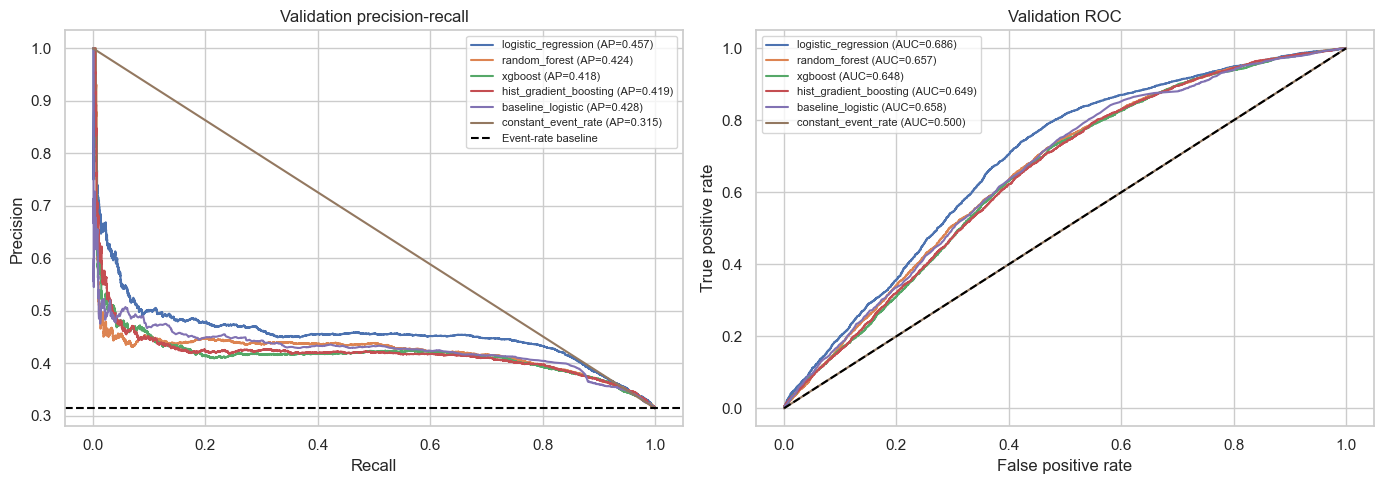

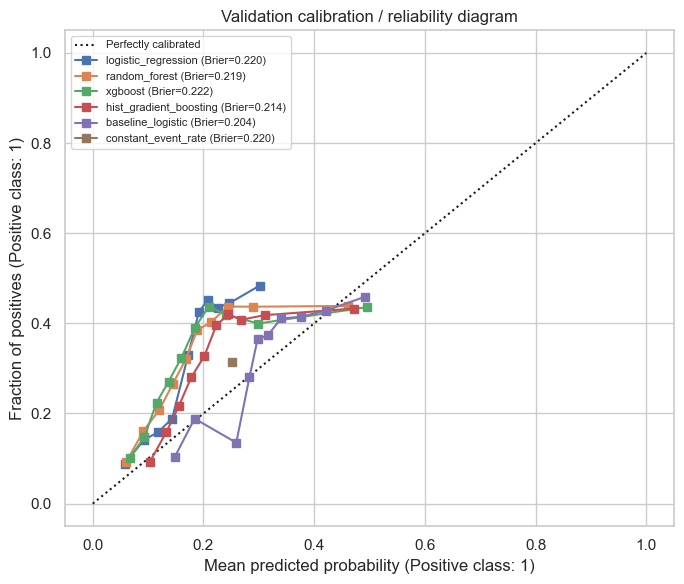

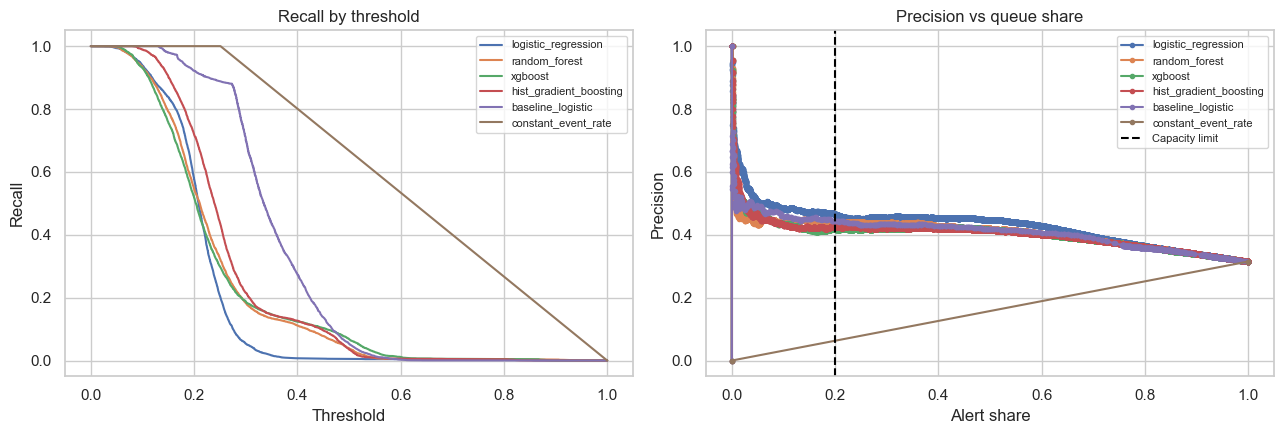

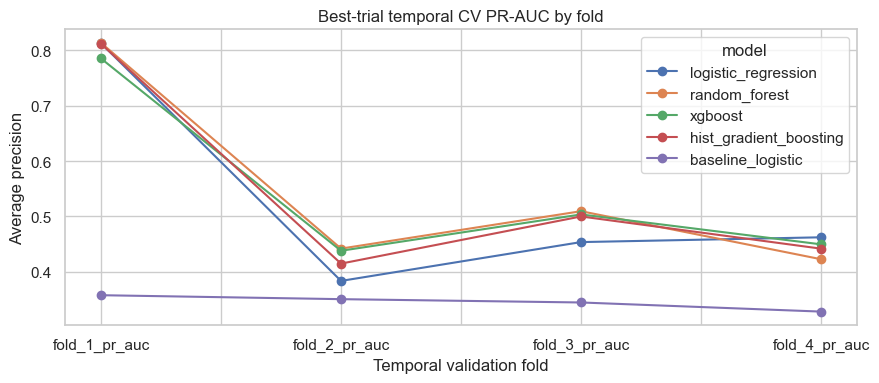

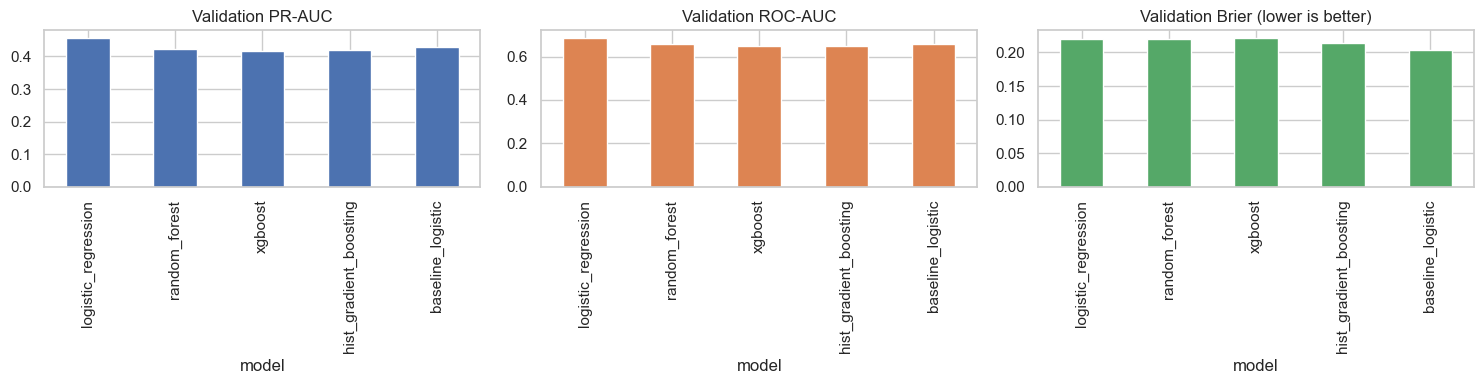

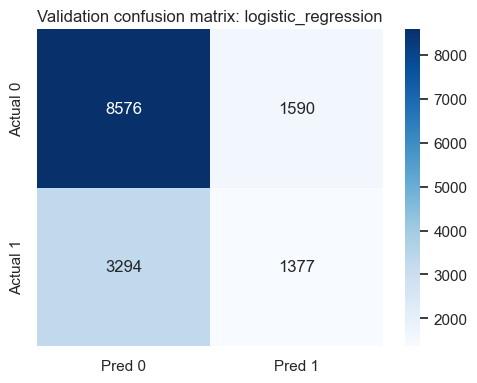

In [7]:
from sklearn.calibration import CalibrationDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, probability in val_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_val, probability)
    axes[0].plot(recall, precision, label=f'{name} (AP={average_precision_score(y_val, probability):.3f})')
    fpr, tpr, _ = roc_curve(y_val, probability)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_val, probability):.3f})')
axes[0].axhline(validation_event_rate, color='black', linestyle='--', label='Event-rate baseline')
axes[0].set(title='Validation precision-recall', xlabel='Recall', ylabel='Precision')
axes[1].plot([0, 1], [0, 1], color='black', linestyle='--')
axes[1].set(title='Validation ROC', xlabel='False positive rate', ylabel='True positive rate')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, probability in val_probabilities.items():
    CalibrationDisplay.from_predictions(y_val, probability, n_bins=10, strategy='quantile',
                                        name=f'{name} (Brier={brier_score_loss(y_val, probability):.3f})', ax=ax)
ax.set_title('Validation calibration / reliability diagram')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, probability in val_probabilities.items():
    candidates = np.unique(np.r_[0.0, probability, 1.000001])
    shares = [(probability >= t).mean() for t in candidates]
    recalls = [recall_score(y_val, probability >= t, zero_division=0) for t in candidates]
    precisions = [precision_score(y_val, probability >= t, zero_division=0) for t in candidates]
    axes[0].plot(candidates, recalls, label=name)
    axes[1].plot(shares, precisions, marker='.', label=name)
axes[0].set(xlabel='Threshold', ylabel='Recall', title='Recall by threshold')
axes[1].axvline(MAX_ALERT_SHARE, color='black', linestyle='--', label='Capacity limit')
axes[1].set(xlabel='Alert share', ylabel='Precision', title='Precision vs queue share')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

cv_plot = cv_results[[f'{folds[i][0]}_pr_auc' for i in range(len(folds))]].T
cv_plot.plot(marker='o', figsize=(9, 4), title='Best-trial temporal CV PR-AUC by fold')
plt.ylabel('Average precision'); plt.xlabel('Temporal validation fold'); plt.tight_layout(); plt.show()

plot_metrics = validation_metrics.loc[[n for n in validation_metrics.index if n != 'constant_event_rate'],
                                      ['validation_pr_auc', 'validation_roc_auc', 'validation_brier']]
plot_metrics.plot(kind='bar', subplots=True, layout=(1, 3), figsize=(15, 4), legend=False,
                  title=['Validation PR-AUC', 'Validation ROC-AUC', 'Validation Brier (lower is better)'])
plt.tight_layout(); plt.show()

selected_prob = val_probabilities[selected_model_name]
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_val, selected_prob >= selected_threshold, labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'],
            yticklabels=['Actual 0', 'Actual 1'], ax=ax)
ax.set_title(f'Validation confusion matrix: {selected_model_name}'); plt.tight_layout(); plt.show()


,segment_type,segment,n,event_rate,pr_auc,roc_auc,precision,recall,alert_share,alerts_in_group,queue_per_1000
0,market_segment,Complementary,125,0.088000,0.163765,0.595295,0.333333,0.090909,0.024000,3,24.000000
1,market_segment,Corporate,570,0.098246,0.144855,0.562517,0.200000,0.035714,0.017544,10,17.543860
2,market_segment,Direct,1404,0.200142,0.252762,0.565942,0.278689,0.060498,0.043447,61,43.447293
3,market_segment,Offline TA/TO,1850,0.143243,0.202307,0.602103,0.305556,0.041509,0.019459,36,19.459459
4,market_segment,Online TA,10827,0.373511,0.478491,0.642910,0.471103,0.332591,0.263693,2855,263.692620
5,lead_time_band,0-7d,2179,0.117944,0.182545,0.585108,0.500000,0.007782,0.001836,4,1.835704
6,lead_time_band,8-30d,2649,0.278218,0.411406,0.664255,0.465035,0.180461,0.107965,286,107.965270
7,lead_time_band,31-90d,4312,0.339981,0.438693,0.649591,0.439960,0.297408,0.229824,991,229.823748
8,lead_time_band,91-180d,3664,0.381004,0.465520,0.617324,0.455157,0.436246,0.365175,1338,365.174672
9,lead_time_band,180d+,2033,0.400885,0.569880,0.689094,0.566092,0.241718,0.171176,348,171.175603


Lead-time subgroup results are diagnostic only until lead_time is verified as-of the intended prediction time.


,feature,importance_mean,importance_std
38,agent_top,0.110052,0.001669
1,lead_time_log,0.048854,0.002200
35,customer_type,0.019050,0.001603
28,prev_cancel_ratio,0.012292,0.001724
11,is_high_season,0.010099,0.000343
16,is_long_stay,0.007801,0.000620
14,stays_in_week_nights,0.007266,0.000621
2,is_last_minute,0.005751,0.001591
22,is_solo,0.005658,0.001295
37,meal,0.005657,0.001004


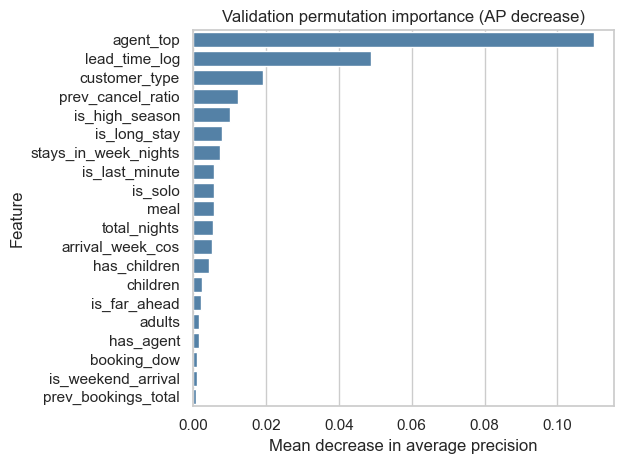

In [8]:
def subgroup_metrics(frame, probability, group_col, threshold, min_n=MIN_SUBGROUP_SIZE):
    records = []
    labels = frame['is_canceled'].astype(int).to_numpy()
    for group, positions in frame.groupby(group_col, dropna=False, observed=True).indices.items():
        positions = np.asarray(positions, dtype=int)
        if len(positions) < min_n:
            continue
        y_group, p_group = labels[positions], probability[positions]
        pred_group = p_group >= threshold
        both_classes = np.unique(y_group).size == 2
        records.append({'segment_type': group_col, 'segment': str(group), 'n': len(positions),
                        'event_rate': y_group.mean(),
                        'pr_auc': average_precision_score(y_group, p_group) if both_classes else np.nan,
                        'roc_auc': roc_auc_score(y_group, p_group) if both_classes else np.nan,
                        'precision': precision_score(y_group, pred_group, zero_division=0),
                        'recall': recall_score(y_group, pred_group, zero_division=0),
                        'alert_share': pred_group.mean(), 'alerts_in_group': int(pred_group.sum()),
                        'queue_per_1000': pred_group.mean() * 1000})
    return pd.DataFrame(records)

lead_time_band = pd.cut(validation['lead_time'], bins=[-np.inf, 7, 30, 90, 180, np.inf],
                        labels=['0-7d', '8-30d', '31-90d', '91-180d', '180d+'], right=True)
subgroup_frame = validation.copy()
subgroup_frame['lead_time_band'] = lead_time_band
subgroup_results = pd.concat([
    subgroup_metrics(subgroup_frame, selected_prob, 'market_segment', selected_threshold),
    subgroup_metrics(subgroup_frame, selected_prob, 'lead_time_band', selected_threshold)
], ignore_index=True)
display(subgroup_results)
print('Lead-time subgroup results are diagnostic only until lead_time is verified as-of the intended prediction time.')

importance_features = baseline_features if selected_model_name == 'baseline_logistic' else feature_cols
importance = permutation_importance(fitted_models[selected_model_name], X_val[importance_features], y_val,
                                    scoring='average_precision', n_repeats=5, random_state=SEED,
                                    n_jobs=-1)
feature_importance = pd.DataFrame({'feature': importance_features,
                                   'importance_mean': importance.importances_mean,
                                   'importance_std': importance.importances_std})
feature_importance = feature_importance.sort_values('importance_mean', ascending=False)
display(feature_importance.head(20))
sns.barplot(data=feature_importance.head(20), x='importance_mean', y='feature', color='steelblue')
plt.title('Validation permutation importance (AP decrease)')
plt.xlabel('Mean decrease in average precision'); plt.ylabel('Feature')
plt.tight_layout(); plt.show()


## 6. Fit model cuối, mở test một lần và tạo file output

Sau khi model/threshold đã được chọn trên validation, fit lại model đã chọn trên train + validation. Threshold vẫn giữ nguyên theo validation. Test 2017 chỉ được dùng ở phần này để đánh giá lần cuối và ghi ra prediction file; do EDA trước đây đã xem nhãn 2017, kết quả test không được diễn giải như một holdout lịch sử hoàn toàn mới.


In [9]:
fit_cohort = pd.concat([train, validation]).sort_values('arrival_date')
if selected_model_name == 'baseline_logistic':
    final_model = make_baseline_pipeline()
    final_features = baseline_features
    final_X_fit = fit_cohort[final_features]
    final_X_test = test[final_features]
else:
    final_model = make_pipeline(selected_model_name, best_params[selected_model_name])
    final_features = feature_cols
    final_X_fit = fit_cohort[final_features]
    final_X_test = test[final_features]
final_model.fit(final_X_fit, fit_cohort['is_canceled'].astype(int))
test_probability = final_model.predict_proba(final_X_test)[:, 1]
raw_test_probability = test_probability.copy()
final_calibrator = None
if CALIBRATION:
    final_oof_p, final_oof_y = oof_probabilities(selected_model_name, best_params.get(selected_model_name),
                                                 fit_cohort, final_features, FINAL_CAL_WINDOWS)
    final_calibrator = fit_calibrator(final_oof_p, final_oof_y, CALIBRATION)
    test_probability = apply_calibrator(final_calibrator, raw_test_probability)
if not np.isfinite(test_probability).all():
    raise ValueError('Test prediction chứa NaN hoặc infinity.')
if test['is_canceled'].isna().any() or not set(test['is_canceled'].unique()).issubset({0, 1}):
    raise ValueError('Test labels must be binary and non-null at final evaluation.')
y_test = test['is_canceled'].astype(int).to_numpy()
test_threshold_metrics = score_at_threshold(y_test, test_probability, selected_threshold)
test_metrics = {'model': selected_model_name, 'threshold_frozen_from_validation': selected_threshold,
                'test_rows': len(test), 'test_event_rate_baseline': float(y_test.mean()),
                'test_pr_auc': average_precision_score(y_test, test_probability),
                'test_roc_auc': roc_auc_score(y_test, test_probability),
                'test_brier': brier_score_loss(y_test, test_probability),
                'test_brier_uncalibrated': brier_score_loss(y_test, raw_test_probability),
                'calibration': CALIBRATION or 'none', **test_threshold_metrics}
test_metrics_df = pd.DataFrame([test_metrics])
display(test_metrics_df.T.rename(columns={0: 'test result'}))
print('Test PR-AUC above event-rate baseline indicates ranking lift; inspect Brier, confusion matrix and queue before any deployment decision.')

test_predictions = pd.DataFrame({'booking_id': test['booking_id'].to_numpy(),
                                 'arrival_date': test['arrival_date'].to_numpy(),
                                 'is_canceled': y_test, 'predicted_probability': test_probability,
                                 'threshold': selected_threshold,
                                 'predicted_label': (test_probability >= selected_threshold).astype(int)})
cv_results.reset_index().to_csv(OUTPUT_DIR / 'temporal_cv_results.csv', index=False)
validation_metrics.reset_index().to_csv(OUTPUT_DIR / 'validation_metrics.csv', index=False)
validation_predictions_all.to_csv(OUTPUT_DIR / 'validation_predictions_all_models.csv', index=False)
validation_predictions_best.to_csv(OUTPUT_DIR / 'validation_predictions_best_model.csv', index=False)
subgroup_results.to_csv(OUTPUT_DIR / 'subgroup_metrics.csv', index=False)
feature_importance.to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)
test_metrics_df.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)
test_predictions.to_csv(OUTPUT_DIR / 'test_predictions_best_model.csv', index=False)
joblib.dump(final_model, OUTPUT_DIR / 'final_model.joblib')
joblib.dump({'model': final_model, 'calibrator': final_calibrator, 'calibration': CALIBRATION,
             'features': final_features, 'threshold': selected_threshold},
            OUTPUT_DIR / 'final_model_bundle.joblib')

selection_md = f'''# Model evaluation report\n\n## Scope and caveats\n- Selected model: **{selected_model_name}**.\n- Final fit: all train + validation rows through 2016-12-31; test begins 2017-01-01.\n- Validation and test were previously inspected in notebook 03 EDA; test is not historically untouched.\n- Dataset is a near-arrival snapshot; results are retrospective and not a production performance guarantee.\n- Frozen threshold: **{selected_threshold:.6f}**, selected on validation to maximize recall subject to alert share <= {MAX_ALERT_SHARE:.0%}.\n- Capacity fallback used: **{capacity_fallback_used}**.\n\n## Validation model comparison\n{selection_table.reset_index().to_string(index=False)}\n\n## Test evaluation (single final evaluation)\n{test_metrics_df.to_string(index=False)}\n\n## Selection rule\nPrefer candidates meeting alert capacity; among them take the validation AP leader and retain candidates within 0.01 AP. Tie-break by temporal CV mean AP, lower fold variability, higher recall then precision at capacity, lower Brier, then simplicity/reproducibility (LR, HGB, RF, XGBoost). Constant event-rate baseline is reference only. No model is selected solely by CV.\n\n## Interpretation checklist\n- Compare PR-AUC with event-rate baseline; report ROC-AUC and Brier alongside threshold metrics.\n- Review precision/recall, confusion matrix, alert share and expected queue per 1,000.\n- Inspect market-segment and lead-time-band subgroup table; small groups (<{MIN_SUBGROUP_SIZE}) are omitted. Lead-time groups are diagnostic until as-of validity is confirmed.\n- Permutation importance is validation-based and associative, not causal.\n- Verify as-of feature availability, calibration drift, operational capacity and false-positive/false-negative costs before deployment.\n'''
selection_md += '\n\n## Temporal CV results\n\n' + cv_results.reset_index().to_string(index=False)
selection_md += '\n\n## Validation subgroup metrics\n\n' + subgroup_results.to_string(index=False)
selection_md += '\n\n## Top validation permutation importance\n\n' + feature_importance.head(15).to_string(index=False) + '\n'
(OUTPUT_DIR / 'model_selection_report.md').write_text(selection_md, encoding='utf-8')
print('Wrote outputs to', OUTPUT_DIR)
print(' - validation_predictions_best_model.csv (requested validation scoring output)')
print(' - test_predictions_best_model.csv, metrics, feature importance, final_model.joblib, model_selection_report.md')


,test result
model,logistic_regression
threshold_frozen_from_validation,0.234928
test_rows,20399
test_event_rate_baseline,0.343742
test_pr_auc,0.528857
test_roc_auc,0.720381
test_brier,0.205936
test_brier_uncalibrated,0.195196
calibration,sigmoid
precision,0.452085


Test PR-AUC above event-rate baseline indicates ranking lift; inspect Brier, confusion matrix and queue before any deployment decision.
Wrote outputs to c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2\artifacts\modeling
 - validation_predictions_best_model.csv (requested validation scoring output)
 - test_predictions_best_model.csv, metrics, feature importance, final_model.joblib, model_selection_report.md


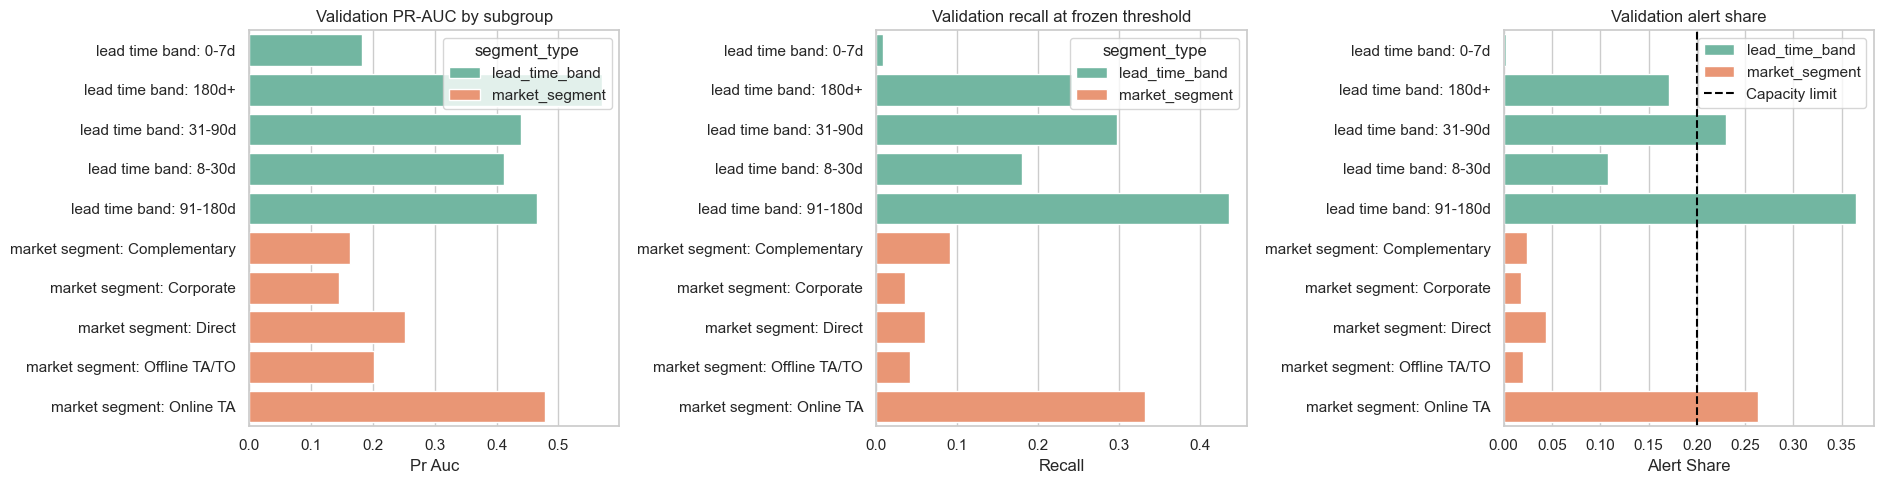

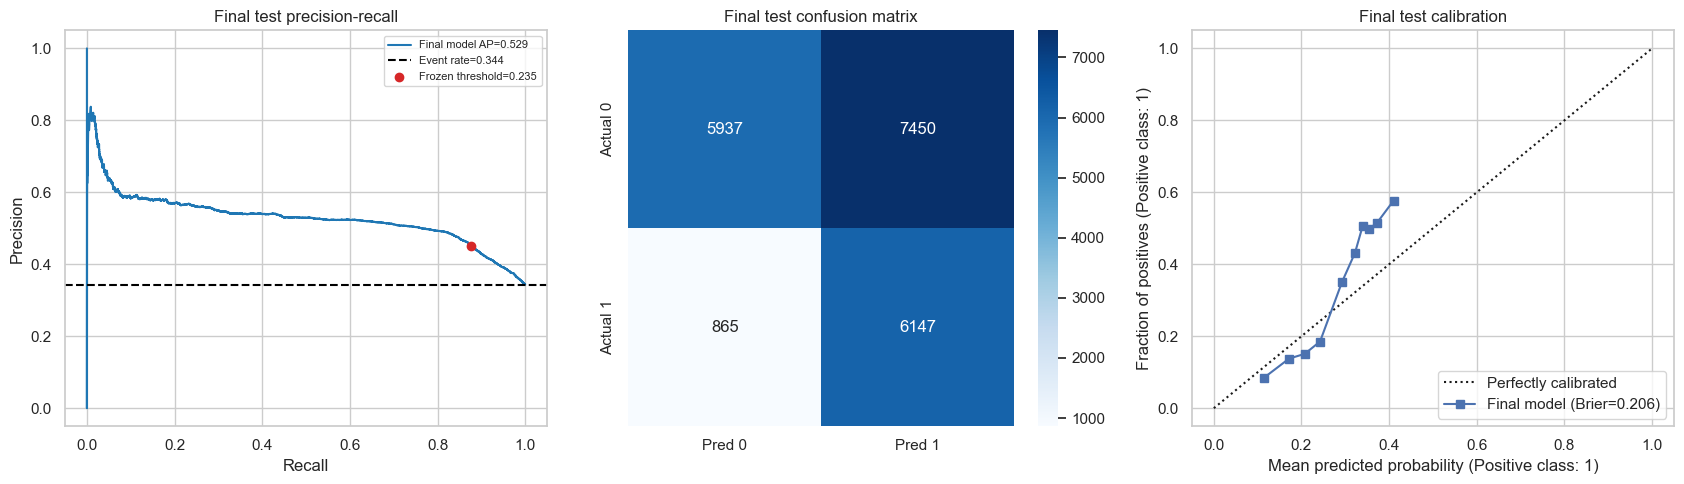

,selected_model,frozen_threshold,test_precision,test_recall,test_alert_share,test_alert_count,expected_alerts_per_1000
0,logistic_regression,0.234928,0.452085,0.87664,0.666552,13597,666.552282


In [10]:
# Hiển thị subgroup plots và đánh giá cuối trên test sau khi đã khóa model/threshold.
plot_subgroups = subgroup_results.copy()
plot_subgroups['group_label'] = plot_subgroups['segment_type'].str.replace('_', ' ') + ': ' + plot_subgroups['segment']
plot_subgroups = plot_subgroups.sort_values(['segment_type', 'segment'])

fig, axes = plt.subplots(1, 3, figsize=(19, max(5, 0.42 * len(plot_subgroups))))
for ax, metric, title in zip(
    axes,
    ['pr_auc', 'recall', 'alert_share'],
    ['Validation PR-AUC by subgroup', 'Validation recall at frozen threshold', 'Validation alert share'],
):
    sns.barplot(data=plot_subgroups, x=metric, y='group_label', hue='segment_type',
                dodge=False, palette='Set2', ax=ax)
    ax.set_title(title)
    ax.set_xlabel(metric.replace('_', ' ').title())
    ax.set_ylabel('')
    if metric == 'alert_share':
        ax.axvline(MAX_ALERT_SHARE, color='black', linestyle='--', label='Capacity limit')
        ax.legend()
plt.tight_layout()
plt.show()

# Test plots are descriptive only; test labels do not affect selection or threshold.
test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_probability)
test_ap = average_precision_score(y_test, test_probability)
final_operating = score_at_threshold(y_test, test_probability, selected_threshold)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(test_recall_curve, test_precision_curve, color='tab:blue', label=f'Final model AP={test_ap:.3f}')
axes[0].axhline(y_test.mean(), color='black', linestyle='--', label=f'Event rate={y_test.mean():.3f}')
axes[0].scatter(final_operating['recall'], final_operating['precision'], color='tab:red', zorder=3,
                label=f'Frozen threshold={selected_threshold:.3f}')
axes[0].set(title='Final test precision-recall', xlabel='Recall', ylabel='Precision')
axes[0].legend(fontsize=8)

sns.heatmap(confusion_matrix(y_test, test_probability >= selected_threshold, labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'],
            yticklabels=['Actual 0', 'Actual 1'], ax=axes[1])
axes[1].set_title('Final test confusion matrix')
CalibrationDisplay.from_predictions(y_test, test_probability, n_bins=10, strategy='quantile',
                                    name=f'Final model (Brier={brier_score_loss(y_test, test_probability):.3f})',
                                    ax=axes[2])
axes[2].set_title('Final test calibration')
plt.tight_layout()
plt.show()

display(pd.DataFrame([{
    'selected_model': selected_model_name,
    'frozen_threshold': selected_threshold,
    'test_precision': final_operating['precision'],
    'test_recall': final_operating['recall'],
    'test_alert_share': final_operating['alert_share'],
    'test_alert_count': final_operating['alerts_in_cohort'],
    'expected_alerts_per_1000': final_operating['queue_per_1000'],
}]))

## 7. Lift@k, khoảng tin cậy và so sánh với rule đơn giản (v2)

- **Lift@k / precision@k / recall@k**: lấy top k% booking điểm cao nhất mỗi cohort. Không phụ thuộc thang xác suất nên không bị ảnh hưởng khi refit làm lệch ngưỡng. Recall tối đa có thể đạt với k% cảnh báo là min(1, k·n / số booking hủy); khi k·n nhỏ hơn số booking hủy thì **precision@k chính là recall so với mức trần đó**, nên đọc precision@k thay vì recall thô khi công suất cảnh báo nhỏ.
- **Block bootstrap theo tuần đến** (các booking cùng tuần tương quan nên không resample từng dòng) → CI 95% cho mọi chỉ số, và CI cho **chênh lệch ghép cặp** giữa model và rule.
- **Rule đơn giản** khách sạn có thể tự áp: (1) xếp theo `lead_time`; (2) tỷ lệ hủy lịch sử theo `market_segment × lead_time band` (làm mượt về tỷ lệ của segment). Rule được fit trên train (cho validation) hoặc train + validation (cho test), cùng quy tắc với model.
- Model chỉ nên được coi là có giá trị tăng thêm nếu CI của chênh lệch so với rule không chứa 0.

Validation: event rate 0.315; model = logistic_regression (đã calibrate: True)


scorer,rule_lead_time,rule_segment_x_leadband,selected_model
metric,,,
lift@10%,"1.325 [1.145, 1.484]","1.254 [1.159, 1.353]","1.537 [1.458, 1.641]"
lift@20%,"1.254 [1.164, 1.342]","1.249 [1.195, 1.332]","1.475 [1.393, 1.555]"
lift@5%,"1.357 [1.053, 1.584]","1.289 [1.169, 1.406]","1.614 [1.497, 1.757]"
pr_auc,"0.383 [0.351, 0.420]","0.396 [0.377, 0.419]","0.457 [0.438, 0.482]"
precision@10%,"0.417 [0.349, 0.484]","0.395 [0.362, 0.432]","0.484 [0.461, 0.517]"
precision@20%,"0.395 [0.358, 0.438]","0.393 [0.372, 0.425]","0.464 [0.440, 0.493]"
precision@5%,"0.427 [0.325, 0.509]","0.406 [0.368, 0.452]","0.508 [0.471, 0.551]"
recall@10%,"0.133 [0.114, 0.148]","0.125 [0.116, 0.135]","0.154 [0.146, 0.164]"
recall@20%,"0.251 [0.233, 0.269]","0.250 [0.239, 0.266]","0.295 [0.279, 0.311]"


Chênh lệch model - rule trên validation (ghép cặp, block bootstrap):


,cohort,model_minus,metric,diff,ci_low,ci_high,ci_excludes_0,boot_n
0,validation,rule_lead_time,pr_auc,0.074681,0.042943,0.102529,True,500
1,validation,rule_lead_time,roc_auc,0.076334,0.057553,0.095032,True,500
2,validation,rule_lead_time,precision@10%,0.066712,-0.000080,0.140772,False,500
3,validation,rule_lead_time,precision@20%,0.069407,0.027003,0.107750,True,500
4,validation,rule_lead_time,lift@10%,0.211903,-0.000270,0.460935,False,500
5,validation,rule_lead_time,lift@20%,0.220465,0.083441,0.355883,True,500
6,validation,rule_lead_time,recall@20%,0.044102,0.016689,0.071184,True,500
7,validation,rule_segment_x_leadband,pr_auc,0.061249,0.047555,0.079056,True,500
8,validation,rule_segment_x_leadband,roc_auc,0.048029,0.037004,0.060361,True,500
9,validation,rule_segment_x_leadband,precision@10%,0.088949,0.053739,0.135977,True,500


Test (chỉ mô tả; không dùng để chọn gì): event rate 0.344


scorer,final_model,rule_lead_time,rule_segment_x_leadband
metric,,,
lift@10%,"1.680 [1.610, 1.768]","1.550 [1.449, 1.644]","1.610 [1.524, 1.678]"
lift@20%,"1.588 [1.526, 1.644]","1.360 [1.301, 1.430]","1.473 [1.419, 1.532]"
lift@5%,"1.714 [1.611, 1.828]","1.708 [1.556, 1.835]","1.577 [1.461, 1.696]"
pr_auc,"0.529 [0.512, 0.547]","0.450 [0.429, 0.472]","0.468 [0.451, 0.487]"
precision@10%,"0.577 [0.553, 0.603]","0.533 [0.491, 0.576]","0.553 [0.523, 0.583]"
precision@20%,"0.546 [0.525, 0.566]","0.467 [0.447, 0.498]","0.506 [0.483, 0.531]"
precision@5%,"0.589 [0.558, 0.622]","0.587 [0.532, 0.638]","0.542 [0.500, 0.586]"
recall@10%,"0.168 [0.161, 0.177]","0.155 [0.145, 0.164]","0.161 [0.152, 0.168]"
recall@20%,"0.318 [0.305, 0.329]","0.272 [0.260, 0.286]","0.295 [0.284, 0.306]"


Chênh lệch model - rule trên test:


,cohort,model_minus,metric,diff,ci_low,ci_high,ci_excludes_0,boot_n
0,test,rule_lead_time,pr_auc,0.079013,0.056058,0.101585,True,500
1,test,rule_lead_time,roc_auc,0.092226,0.078439,0.106291,True,500
2,test,rule_lead_time,precision@10%,0.044608,-0.002286,0.094420,False,500
3,test,rule_lead_time,precision@20%,0.078431,0.047889,0.105666,True,500
4,test,rule_lead_time,lift@10%,0.129771,-0.006752,0.275894,False,500
5,test,rule_lead_time,lift@20%,0.228169,0.137914,0.305225,True,500
6,test,rule_lead_time,recall@20%,0.045636,0.027586,0.061045,True,500
7,test,rule_segment_x_leadband,pr_auc,0.061047,0.047399,0.075083,True,500
8,test,rule_segment_x_leadband,roc_auc,0.042868,0.033582,0.053220,True,500
9,test,rule_segment_x_leadband,precision@10%,0.024020,-0.004895,0.063830,False,500


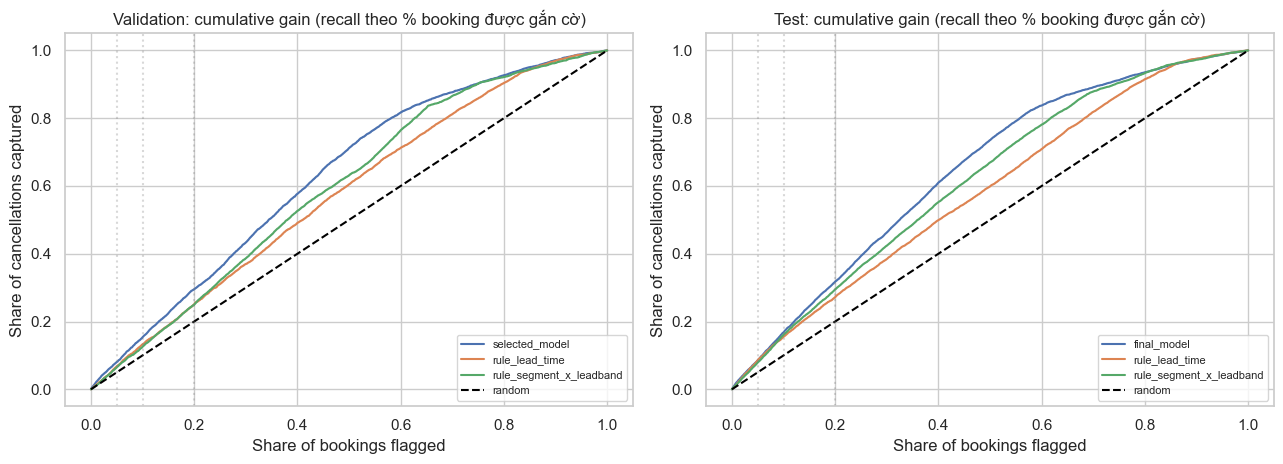

Wrote topk_bootstrap_metrics.csv, model_vs_rules_diff.csv and appended to model_selection_report.md


In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score

LEAD_BINS = [-np.inf, 7, 30, 90, 180, np.inf]
LEAD_LABELS = ['0-7d', '8-30d', '31-90d', '91-180d', '180d+']

def lead_band(series):
    return pd.cut(series, bins=LEAD_BINS, labels=LEAD_LABELS, right=True).astype(str)

def fit_rule_table(frame, m=30):
    f = frame.assign(_band=lead_band(frame['lead_time']), _y=frame['is_canceled'].astype(int))
    glob = float(f['_y'].mean())
    seg = f.groupby('market_segment')['_y'].agg(['sum', 'count'])
    seg_rate = ((seg['sum'] + m * glob) / (seg['count'] + m)).to_dict()
    cell_map = {k: (r['sum'], r['count']) for k, r in
                f.groupby(['market_segment', '_band'])['_y'].agg(['sum', 'count']).iterrows()}
    return glob, seg_rate, cell_map, m

def score_rule(frame, table):
    glob, seg_rate, cell_map, m = table
    out = []
    for seg_value, band in zip(frame['market_segment'], lead_band(frame['lead_time'])):
        base = seg_rate.get(seg_value, glob)
        s, c = cell_map.get((seg_value, band), (0.0, 0.0))
        out.append((s + m * base) / (c + m))
    return np.asarray(out, dtype=float)

def topk_stats(y, order, share):
    k = max(1, int(np.ceil(share * len(y))))
    hits = y[order[:k]].sum()
    pos = max(int(y.sum()), 1)
    precision, recall = hits / k, hits / pos
    return precision, recall, precision / y.mean(), recall / min(1.0, k / pos)

def metric_bundle(y, p, jitter):
    order = np.lexsort((jitter, -p))          # xếp theo điểm giảm dần; hoà thì theo jitter ngẫu nhiên cố định
    out = {'pr_auc': average_precision_score(y, p), 'roc_auc': roc_auc_score(y, p)}
    for share in TOPK_SHARES:
        prec, rec, lift, eff = topk_stats(y, order, share)
        tag = int(round(share * 100))
        out[f'precision@{tag}%'] = prec
        out[f'recall@{tag}%'] = rec
        out[f'lift@{tag}%'] = lift
    return out

def block_bootstrap(y, scores, weeks, jitter, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    uniq, inverse = np.unique(weeks, return_inverse=True)
    members = [np.flatnonzero(inverse == i) for i in range(len(uniq))]
    store = {name: [] for name in scores}
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        idx = np.concatenate([members[i] for i in pick])
        yb = y[idx]
        if yb.min() == yb.max():
            continue
        for name, s in scores.items():           # cùng idx cho mọi scorer -> chênh lệch ghép cặp
            store[name].append(metric_bundle(yb, s[idx], jitter[idx]))
    return {name: pd.DataFrame(v) for name, v in store.items()}

def evaluate_scorers(label, frame, scores, model_key):
    y = frame['is_canceled'].astype(int).to_numpy()
    weeks = frame['arrival_date'].dt.to_period('W').astype(str).to_numpy()
    jitter = np.random.default_rng(SEED).random(len(y))
    boot = block_bootstrap(y, scores, weeks, jitter)
    rows = []
    for name, s in scores.items():
        point = metric_bundle(y, s, jitter)
        for metric, value in point.items():
            lo, hi = boot[name][metric].quantile([0.025, 0.975])
            rows.append({'cohort': label, 'scorer': name, 'metric': metric,
                         'value': value, 'ci_low': lo, 'ci_high': hi})
    table = pd.DataFrame(rows)
    key_metrics = ['pr_auc', 'roc_auc', 'precision@10%', 'precision@20%', 'lift@10%', 'lift@20%', 'recall@20%']
    key_metrics = [m for m in key_metrics if m in boot[model_key].columns]
    diffs = []
    point_model = metric_bundle(y, scores[model_key], jitter)
    for name in scores:
        if name == model_key:
            continue
        point_other = metric_bundle(y, scores[name], jitter)
        for metric in key_metrics:
            d = boot[model_key][metric] - boot[name][metric]
            lo, hi = d.quantile([0.025, 0.975])
            diffs.append({'cohort': label, 'model_minus': name, 'metric': metric,
                          'diff': point_model[metric] - point_other[metric], 'ci_low': lo, 'ci_high': hi,
                          'ci_excludes_0': bool(lo > 0 or hi < 0), 'boot_n': len(d)})
    return table, pd.DataFrame(diffs), y, jitter

def fmt(table, scorers):
    t = table[table.scorer.isin(scorers)].copy()
    t['value (95% CI)'] = t.apply(lambda r: f"{r.value:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
    return t.pivot(index='metric', columns='scorer', values='value (95% CI)')

lead_median = train['lead_time'].median()
val_scores = {
    'selected_model': np.asarray(val_probabilities[selected_model_name], dtype=float),
    'rule_lead_time': validation['lead_time'].astype(float).fillna(lead_median).to_numpy(),
    'rule_segment_x_leadband': score_rule(validation, fit_rule_table(train)),
}
test_scores = {
    'final_model': np.asarray(test_probability, dtype=float),
    'rule_lead_time': test['lead_time'].astype(float).fillna(lead_median).to_numpy(),
    'rule_segment_x_leadband': score_rule(test, fit_rule_table(fit_cohort)),
}

val_table, val_diff, y_val_arr, val_jit = evaluate_scorers('validation', validation, val_scores, 'selected_model')
test_table, test_diff, y_test_arr, test_jit = evaluate_scorers('test', test, test_scores, 'final_model')

print(f'Validation: event rate {y_val_arr.mean():.3f}; model = {selected_model_name} (đã calibrate: {bool(CALIBRATION)})')
display(fmt(val_table, list(val_scores)))
print('Chênh lệch model - rule trên validation (ghép cặp, block bootstrap):')
display(val_diff)
print(f'Test (chỉ mô tả; không dùng để chọn gì): event rate {y_test_arr.mean():.3f}')
display(fmt(test_table, list(test_scores)))
print('Chênh lệch model - rule trên test:')
display(test_diff)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (title, y_arr, scores, jit) in zip(axes, [('Validation', y_val_arr, val_scores, val_jit),
                                                   ('Test', y_test_arr, test_scores, test_jit)]):
    for name, s in scores.items():
        order = np.lexsort((jit, -s))
        gain = np.cumsum(y_arr[order]) / y_arr.sum()
        ax.plot(np.arange(1, len(y_arr) + 1) / len(y_arr), gain, label=name)
    ax.plot([0, 1], [0, 1], '--', color='black', label='random')
    for share in TOPK_SHARES:
        ax.axvline(share, color='grey', alpha=0.3, linestyle=':')
    ax.set(title=f'{title}: cumulative gain (recall theo % booking được gắn cờ)',
           xlabel='Share of bookings flagged', ylabel='Share of cancellations captured')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.concat([val_table, test_table]).to_csv(OUTPUT_DIR / 'topk_bootstrap_metrics.csv', index=False)
pd.concat([val_diff, test_diff]).to_csv(OUTPUT_DIR / 'model_vs_rules_diff.csv', index=False)
with open(OUTPUT_DIR / 'model_selection_report.md', 'a', encoding='utf-8') as fh:
    fh.write('\n\n## Lift@k, bootstrap CI và so sánh với rule đơn giản\n\n')
    fh.write('Block bootstrap theo tuần đến, %d lần; CI 95%%. Rule fit trên dữ liệu cùng cohort huấn luyện.\n\n' % N_BOOT)
    fh.write('### Validation\n\n' + fmt(val_table, list(val_scores)).to_string() + '\n\n')
    fh.write(val_diff.to_string(index=False) + '\n\n### Test\n\n')
    fh.write(fmt(test_table, list(test_scores)).to_string() + '\n\n' + test_diff.to_string(index=False) + '\n')
print('Wrote topk_bootstrap_metrics.csv, model_vs_rules_diff.csv and appended to model_selection_report.md')

## Deliverables khi chạy

Thư mục `artifacts/modeling/` sẽ chứa predictions của mọi model và model tốt nhất trên validation, predictions/evaluation trên test, temporal CV + validation/subgroup/test metrics, permutation importance, serialized final model và `model_selection_report.md`. Trước khi dùng model, cần xác minh snapshot/as-of semantics, chọn chi phí vận hành threshold với business owner và chạy quy trình scoring trên dữ liệu mới có schema tương thích.
